# PPO (Proximal Policy Optimization) Notebook

In [1]:
import gym, warnings, os, torch, random, gc
import numpy as np
import pandas as pd
from models import PolicyNet, SparsePolicyNet
from rl_utils.ppo import PPOTrainer, train
from  utils import (
    xavier_init_weights, 
    save_model_params, 
    plot_train_performance, 
    plot_result_dataframe,
    run_evaluation,
)
from typing import Union, Optional

warnings.filterwarnings("ignore")
os.environ["ENV_SEED"] = "3407"
torch.set_default_dtype(torch.float32)

In [2]:
SEED = int(os.environ["ENV_SEED"])
random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
np.random.seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [3]:
policy_lr = 2.5e-5
value_lr = 2.5e-4
gamma = 0.99
lambda_ = 0.97
epsilon = 0.2
episodes = 400
kl_div_coef = 0.007
n_policy_train_steps = 100
n_value_train_steps = 100
hidden_size = 128

train_env = gym.make("CartPole-v1")
eval_env = gym.make("CartPole-v1", render_mode="human")
results_dir = "sparsification_results"

max_rollout_steps = train_env._max_episode_steps
observation_space = train_env.observation_space._shape[0]
action_space = train_env.action_space.n

sparsity_penalty_coefs = np.array([1e-05, 5e-5, 1e-4, 5e-4, 1e-3, 5e-3, 1e-2, 5e-2, 1e-1, 5e-1])

In [4]:
def run_train(
        policy_agent: Union[PolicyNet, SparsePolicyNet], 
        value_agent: Union[PolicyNet, SparsePolicyNet],
        policy_optimizer: torch.optim.Optimizer,
        value_optimizer: torch.optim.Optimizer,
        policy_weights_filename: Optional[str]=None,
        save_best_weights: bool=True,
        sparse_penalty_coef: Optional[float]=None,
        plot_performance: bool=True,
    ):

    if isinstance(policy_agent, SparsePolicyNet):
        assert sparse_penalty_coef is not None

    if save_best_weights:
        assert policy_weights_filename is not None
    
    train_env = gym.make("CartPole-v1")
    ppo = PPOTrainer(
        policy_agent,
        value_agent, 
        policy_optimizer, 
        value_optimizer, 
        epsilon=epsilon, 
        kl_div_coef=kl_div_coef, 
        n_policy_train_steps=n_policy_train_steps, 
        n_value_train_steps=n_value_train_steps, 
        sparse_penalty_coef=sparse_penalty_coef
    )

    os.makedirs("params", exist_ok=True)

    try:
        train_performance, best_rewards = train(
            train_env, 
            ppo, 
            n_episodes=episodes, 
            gamma=gamma, 
            lambda_=lambda_, 
            max_rollout_steps=max_rollout_steps,
            max_episode_reward=train_env._max_episode_steps,
            continue_after_max_reward=False,
            policy_weights_filename=policy_weights_filename,
            save_best_weights=save_best_weights,
            verbose=False,
            close_env=True,
        )
    except KeyboardInterrupt:
        train_env.close()

    if plot_performance:
        plot_train_performance(train_performance, best_rewards)

    convergence_steps = len(train_performance["rewards"])
    return convergence_steps

## Train and Evaluate Dense Policy

 14%|█▍        | 57/400 [00:24<02:28,  2.30it/s]


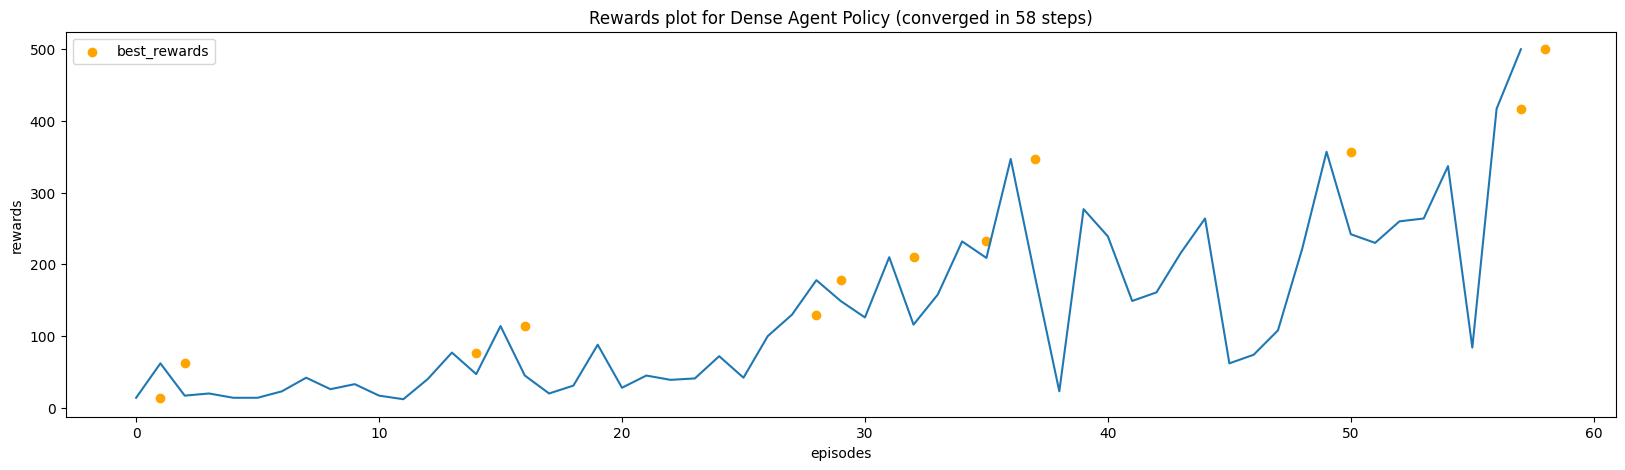

Evaluation reward of policy: 500.0
Average policy entropy of policy: 0.6115037
Pole angle variance of policy: 2.31e-05 rads


(500.0, 0.6115036572813988, 2.3060248372842353e-05)

In [5]:
dense_policy_agent = PolicyNet(observation_space, action_space, hidden_size)
dense_policy_agent.to(os.getenv("DEVICE"))
dense_value_agent = PolicyNet(observation_space, 1, hidden_size)
dense_value_agent.to(os.getenv("DEVICE"))

dense_policy_agent.apply(xavier_init_weights)
dense_value_agent.apply(xavier_init_weights)

dense_policy_optimizer = torch.optim.Adam(dense_policy_agent.parameters(), lr=policy_lr)
dense_value_optimizer = torch.optim.Adam(dense_value_agent.parameters(), lr=value_lr)
policy_weights_filename = "CartPolev1_PPO_dense_policy_agent.pth.tar"

run_train(
    dense_policy_agent, 
    dense_value_agent, 
    dense_policy_optimizer, 
    dense_value_optimizer, 
    policy_weights_filename, 
    plot_performance=True
)

run_evaluation(dense_policy_agent, verbose=True)

## Train and Evaluate Sparse Policy Against Different Sparsity Coefficents

Training sparse policy with sparsity coef: 1e-05



 20%|██        | 82/400 [01:14<04:47,  1.10it/s]


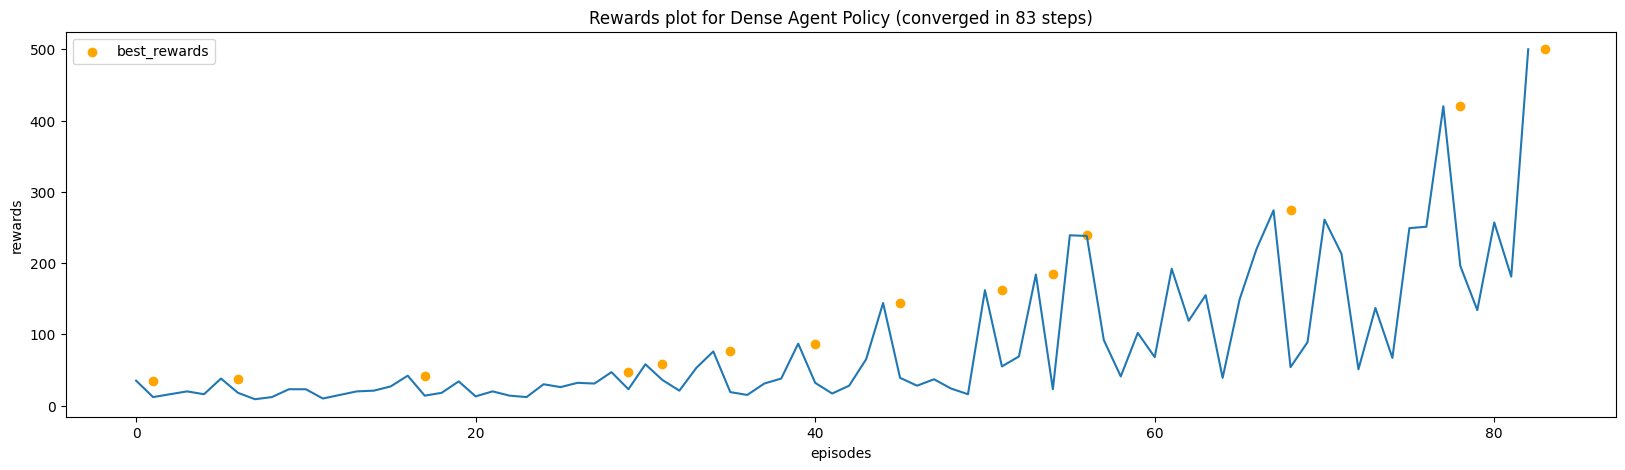

Training sparse policy with sparsity coef: 5e-05



 33%|███▎      | 133/400 [02:14<04:29,  1.01s/it]


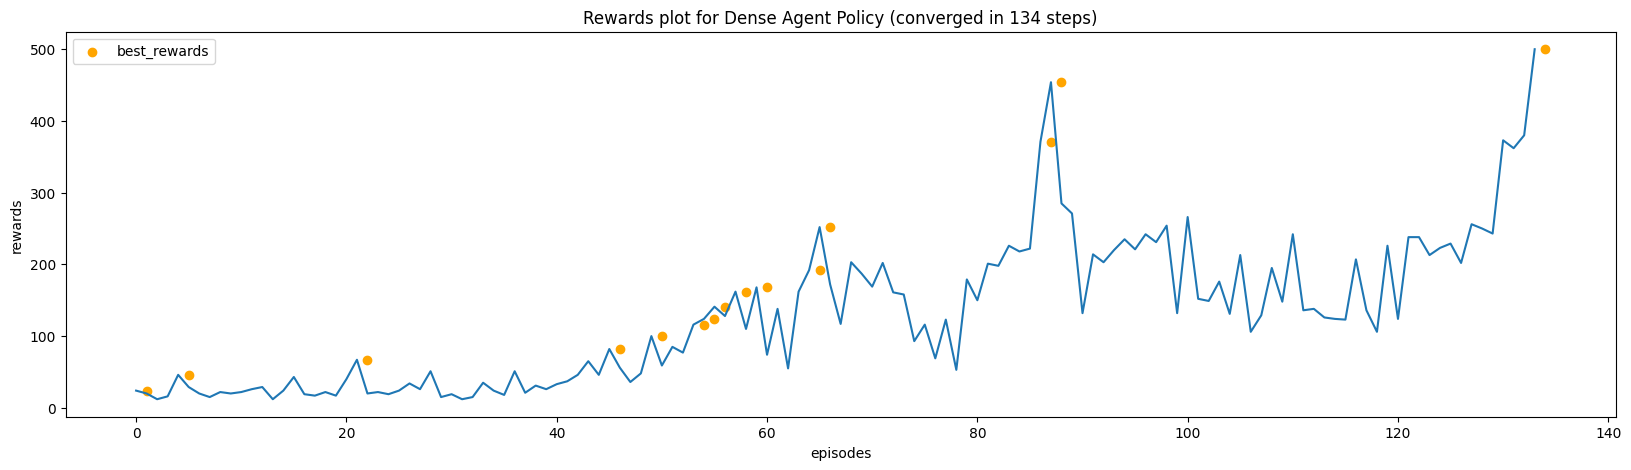

Training sparse policy with sparsity coef: 0.0001



 22%|██▏       | 88/400 [01:25<05:02,  1.03it/s]


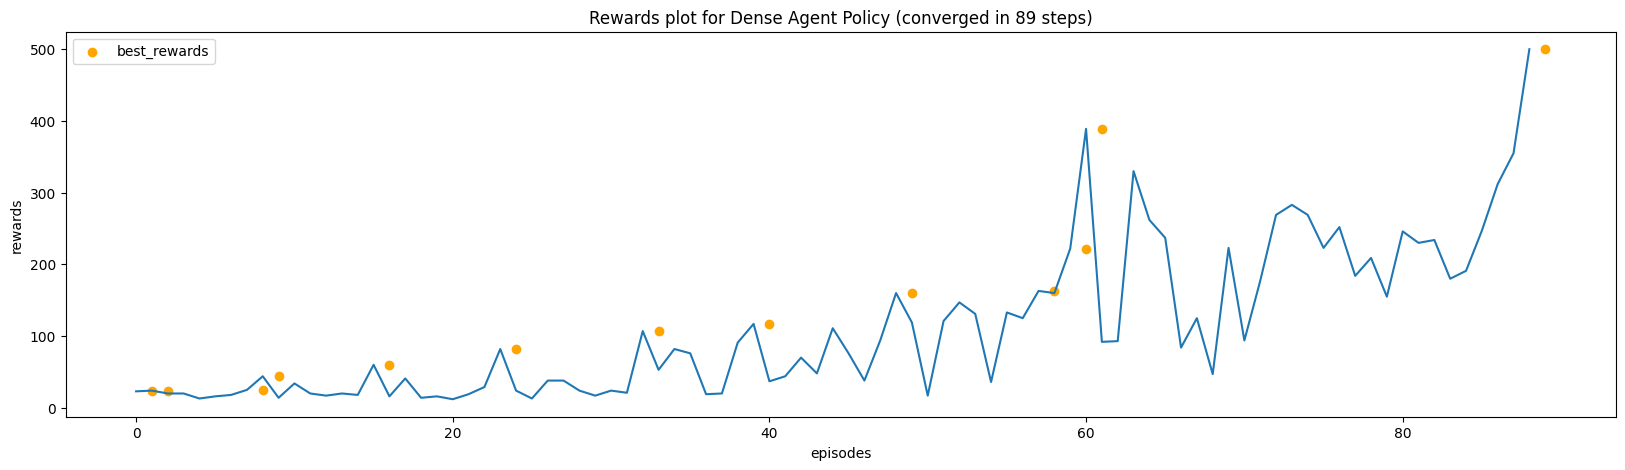

Training sparse policy with sparsity coef: 0.0005



 20%|██        | 80/400 [01:07<04:30,  1.18it/s]


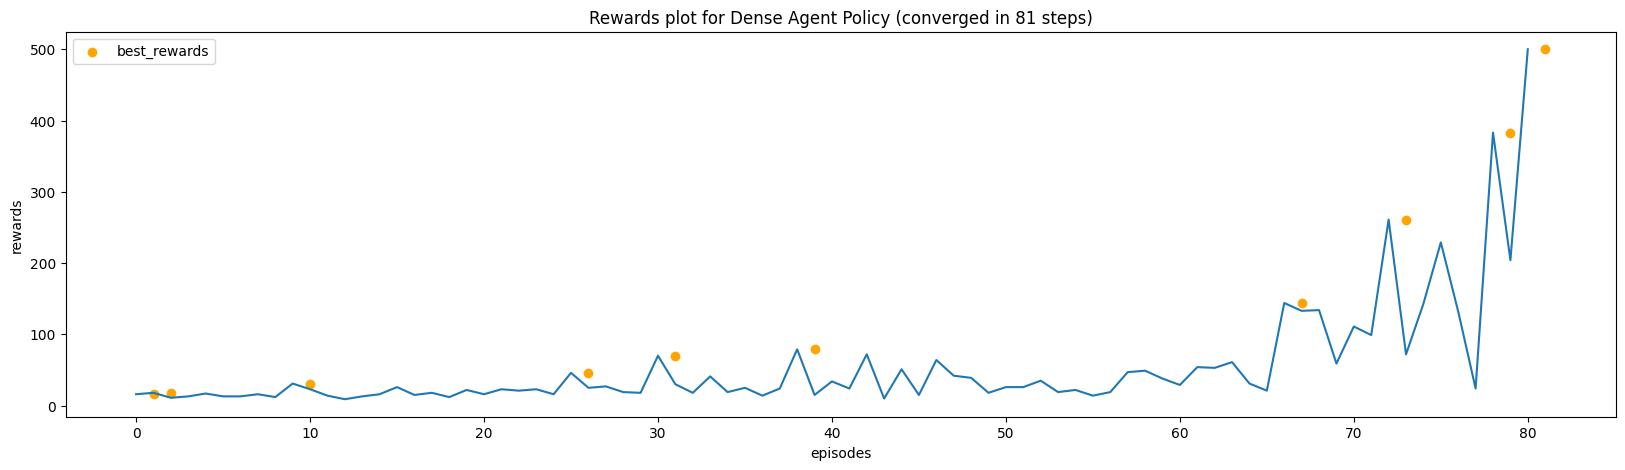

Training sparse policy with sparsity coef: 0.001



 21%|██        | 83/400 [01:18<04:58,  1.06it/s]


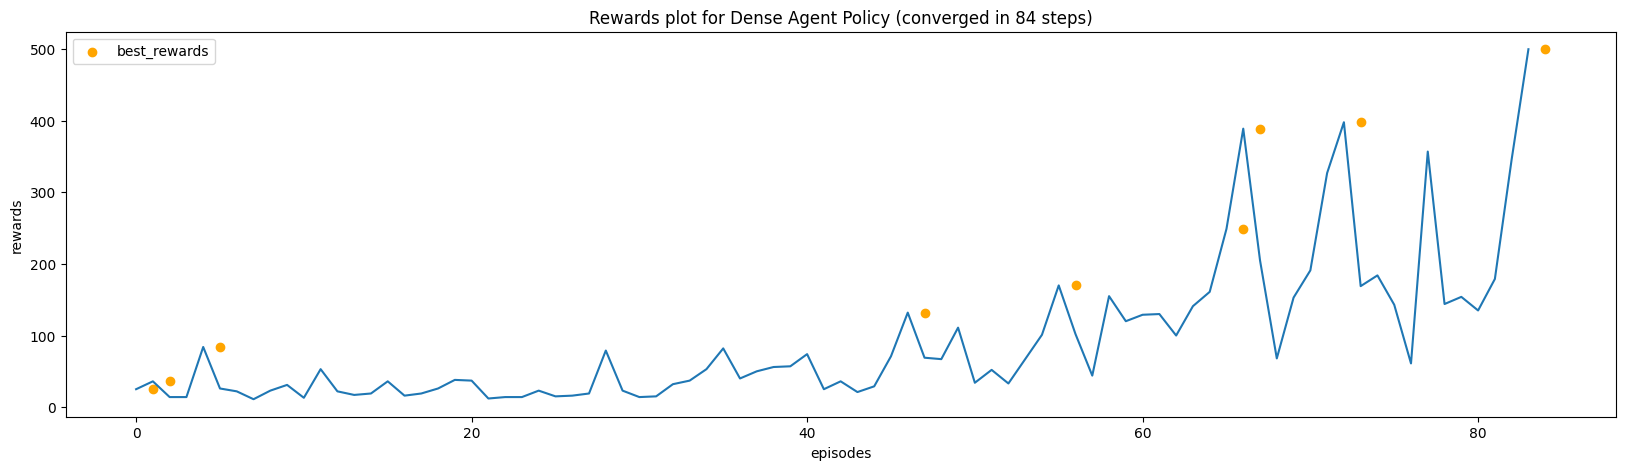

Training sparse policy with sparsity coef: 0.005



 27%|██▋       | 108/400 [01:41<04:33,  1.07it/s]


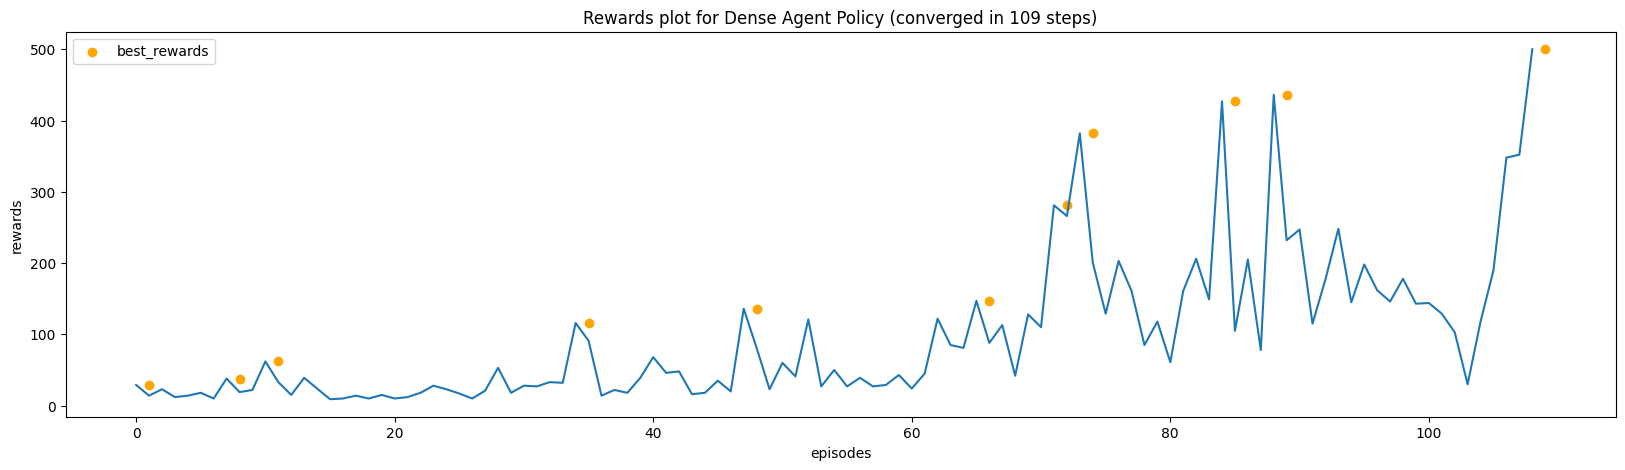

Training sparse policy with sparsity coef: 0.01



 23%|██▎       | 92/400 [01:26<04:50,  1.06it/s]


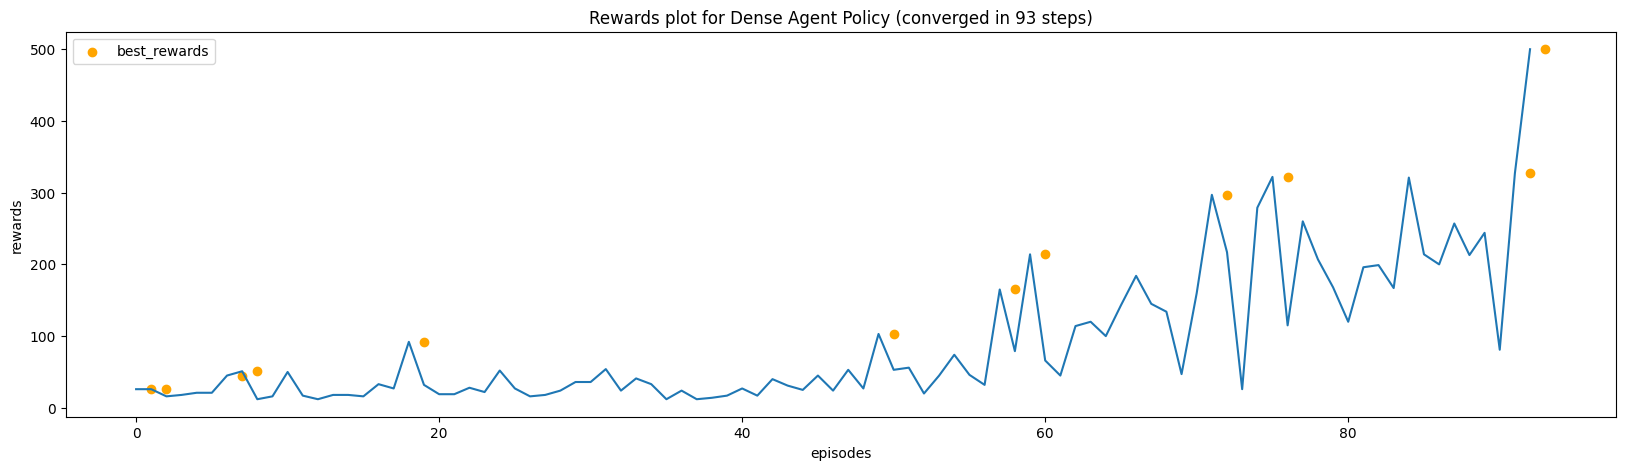

Training sparse policy with sparsity coef: 0.05



 32%|███▏      | 127/400 [02:04<04:28,  1.02it/s]


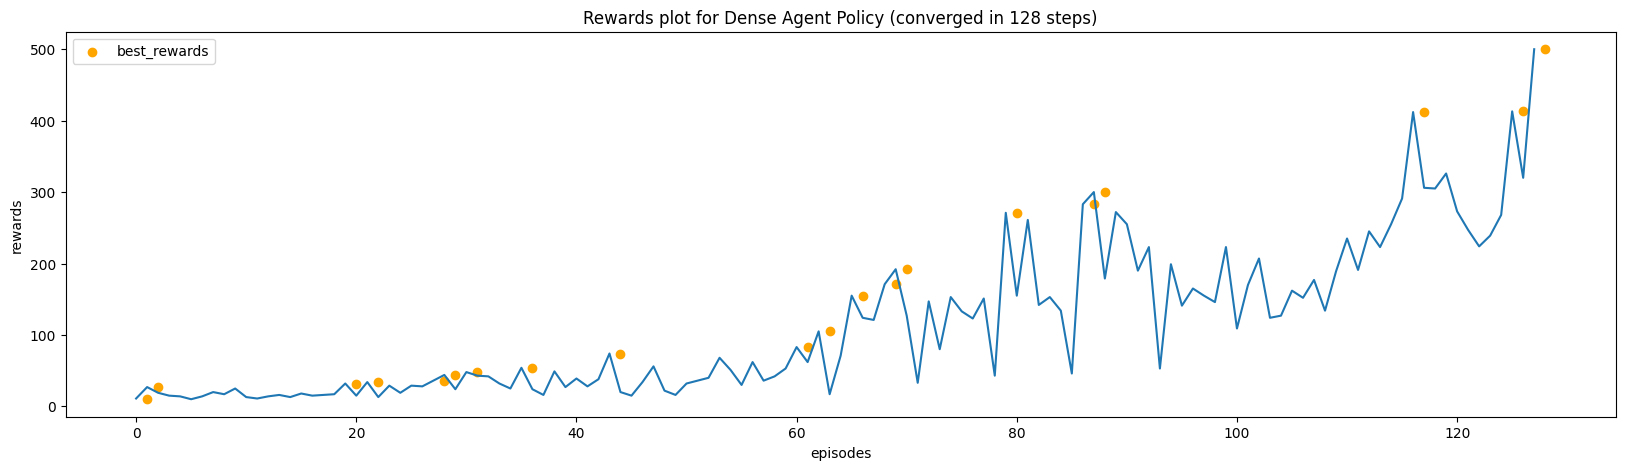

Training sparse policy with sparsity coef: 0.1



100%|██████████| 400/400 [07:03<00:00,  1.06s/it]


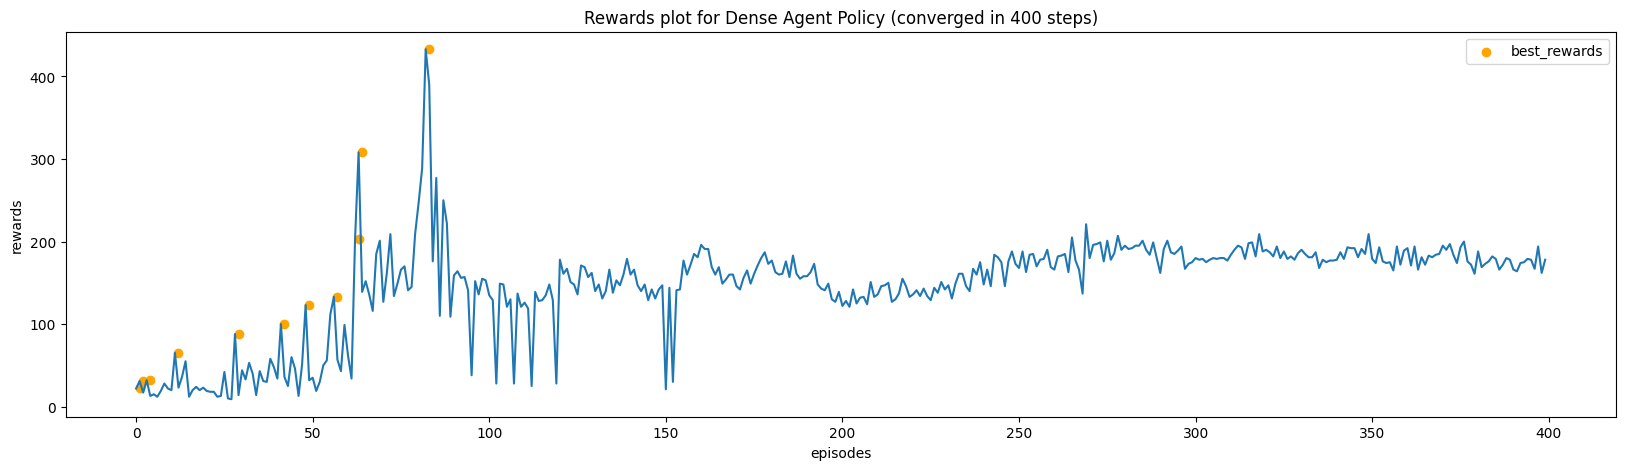

Training sparse policy with sparsity coef: 0.5



 29%|██▉       | 117/400 [01:42<04:08,  1.14it/s]


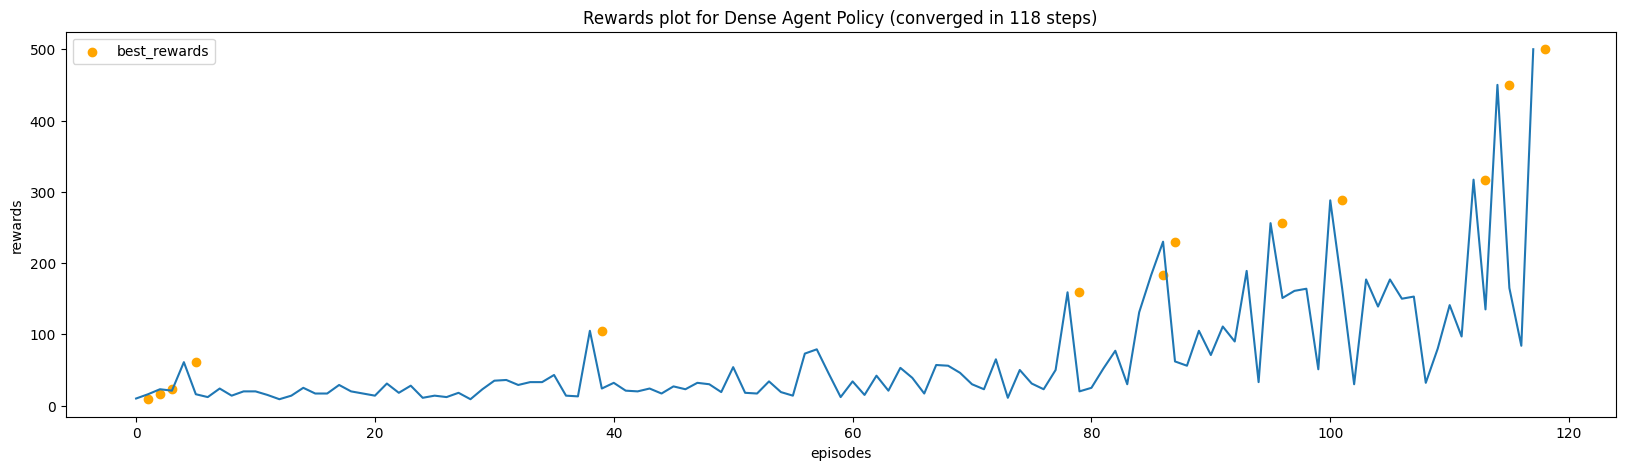

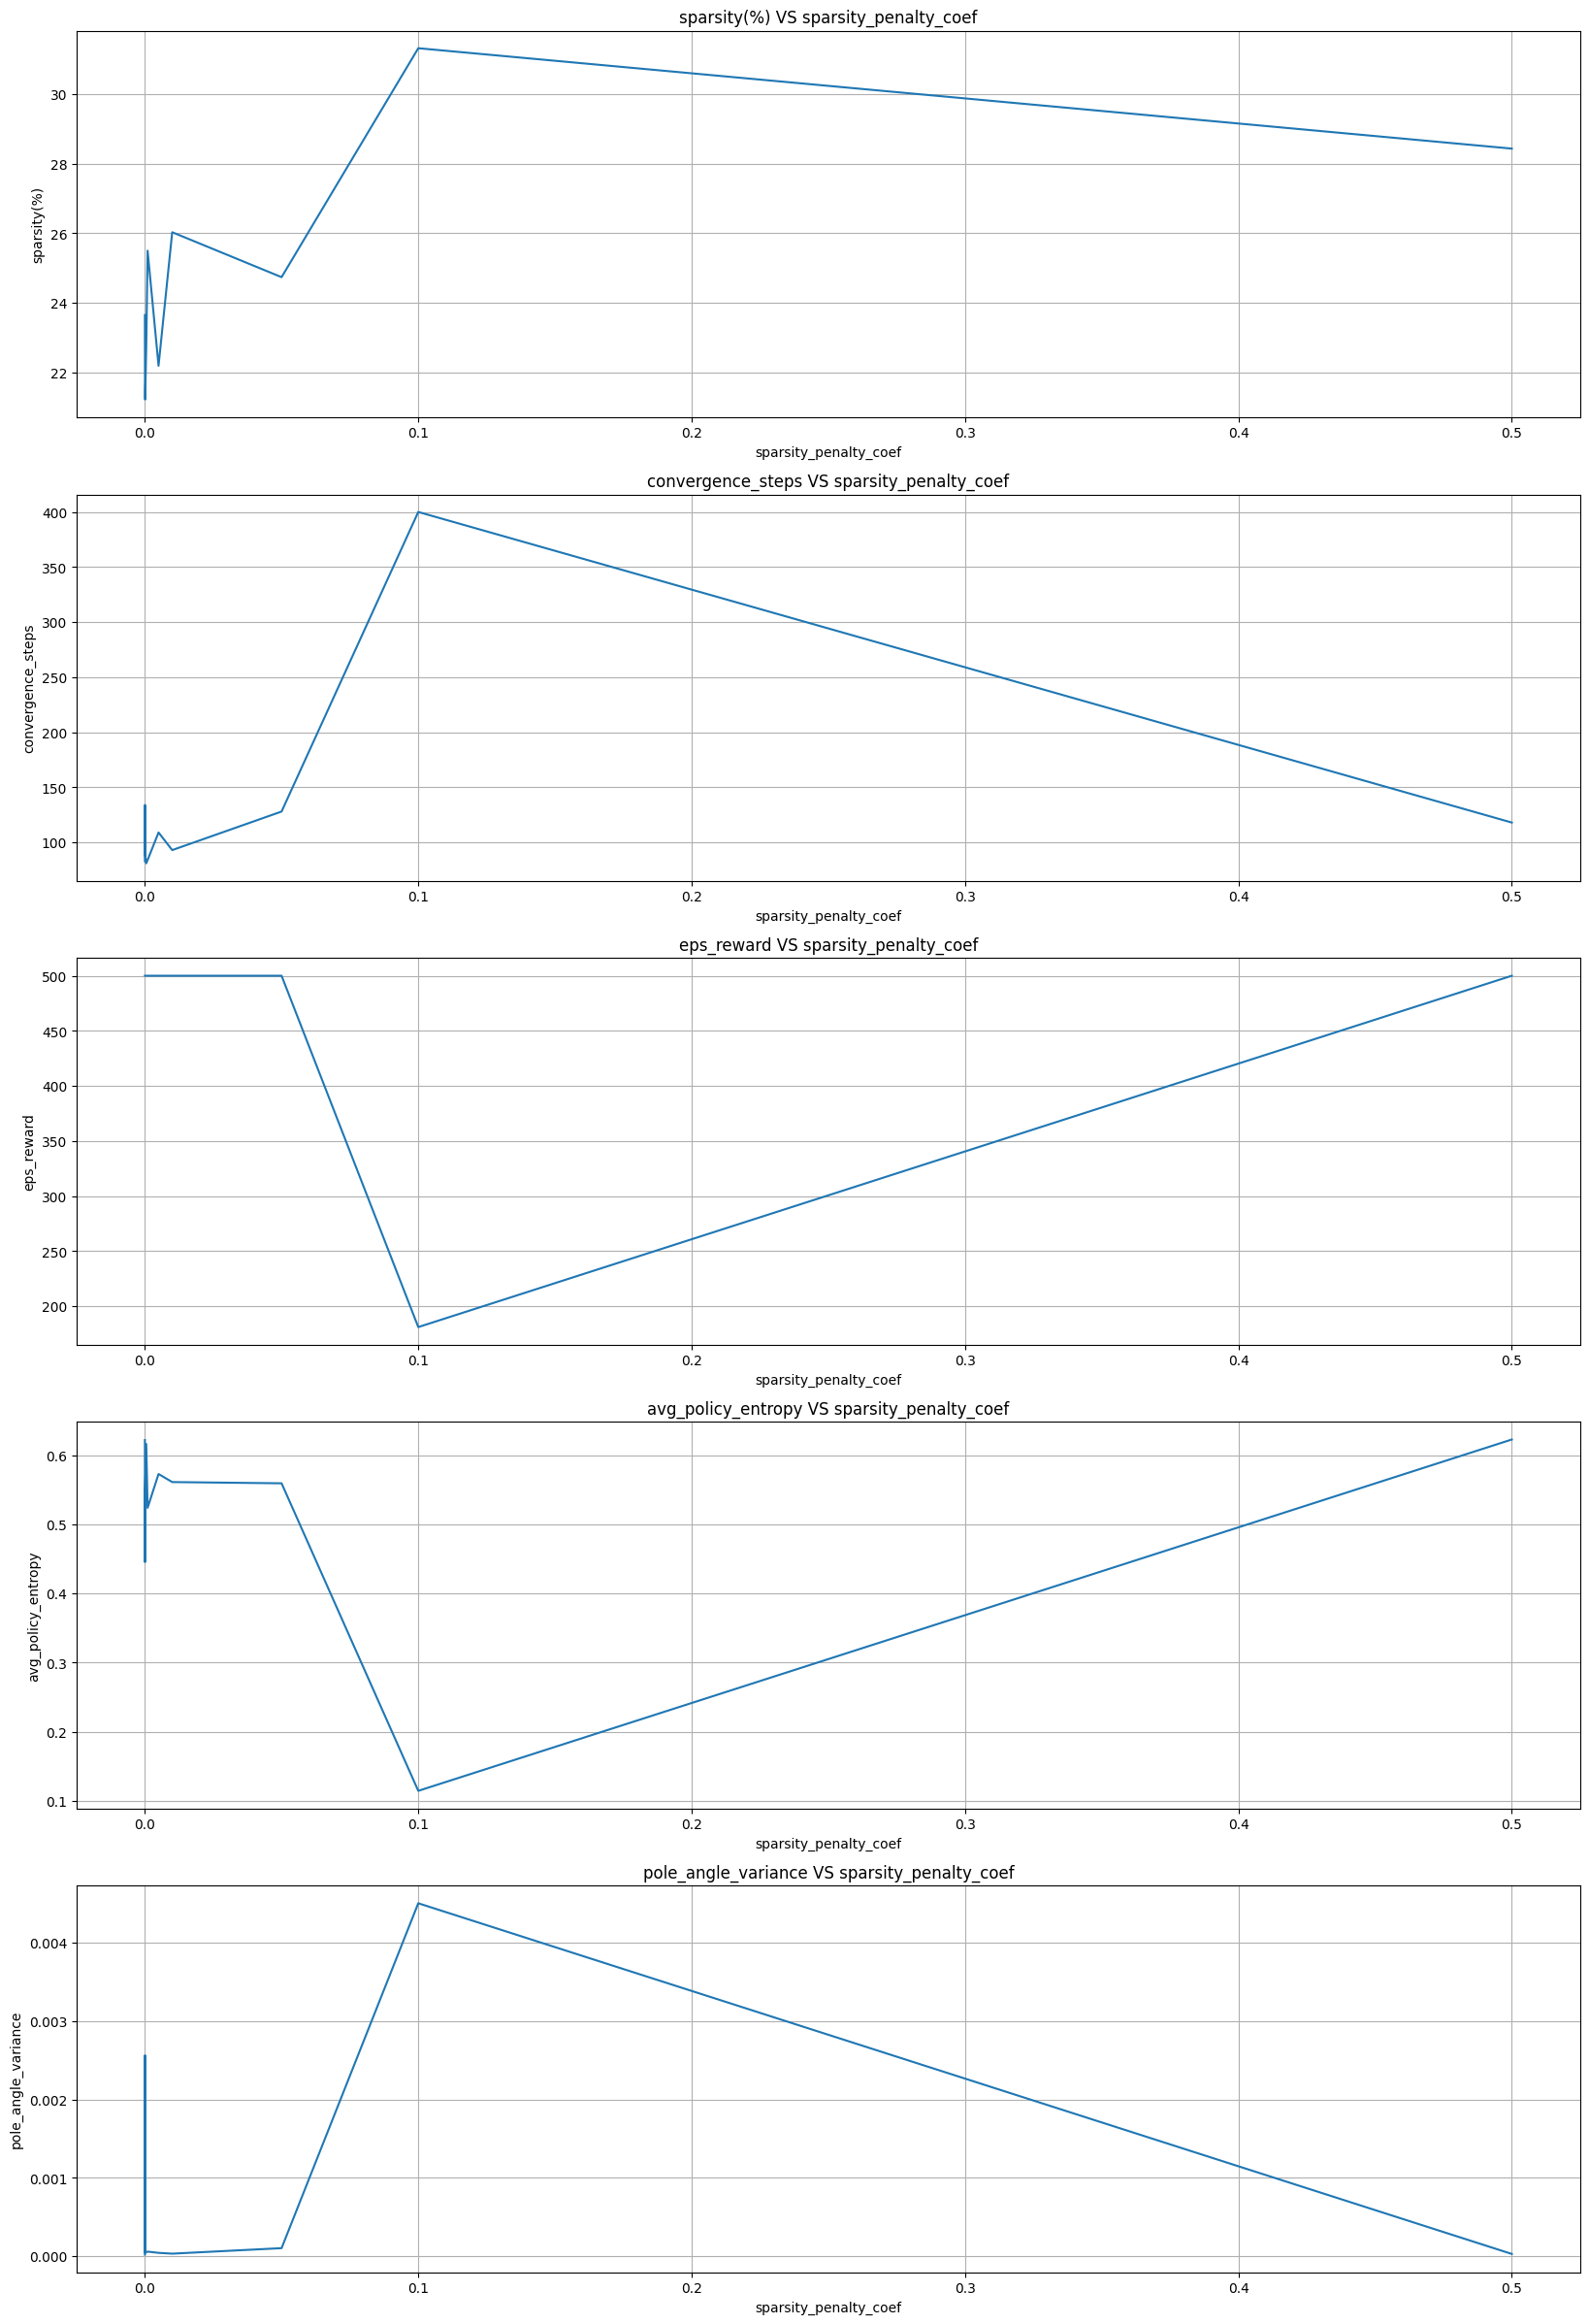

,sparsity_penalty_coef,sparsity(%),convergence_steps,eps_reward,avg_policy_entropy,pole_angle_variance
0,0.00001,23.648071,83,500.0,0.622084,0.000021
1,0.00005,21.405029,134,500.0,0.445460,0.002565
2,0.00010,21.221924,89,500.0,0.548476,0.000044
3,0.00050,22.738647,81,500.0,0.616323,0.000052
4,0.00100,25.497437,84,500.0,0.524039,0.000059
5,0.00500,22.192383,109,500.0,0.572955,0.000043
6,0.01000,26.028442,93,500.0,0.561282,0.000033
7,0.05000,24.737549,128,500.0,0.559488,0.000103
8,0.10000,31.314087,400,181.0,0.114371,0.004504
9,0.50000,28.430176,118,500.0,0.622888,0.000029


In [6]:
result = dict()
result["sparsity_penalty_coef"] = []
result["sparsity(%)"] = []
result["convergence_steps"] = []
result["eps_reward"] = []
result["avg_policy_entropy"] = []
result["pole_angle_variance"] = []

policy_weights_filename = "CartPolev1_PPO_sparse_policy_agent.pth.tar"
best_score = -np.inf

for coef in sparsity_penalty_coefs:
    sparse_policy_agent = SparsePolicyNet(observation_space, action_space, hidden_size, sparsity_on_eval=True)
    sparse_policy_agent.to(os.getenv("DEVICE"))
    sparse_value_agent = SparsePolicyNet(observation_space, 1, hidden_size, sparsity_on_eval=True)
    sparse_value_agent.to(os.getenv("DEVICE"))

    sparse_policy_agent.apply(xavier_init_weights)
    sparse_value_agent.apply(xavier_init_weights)

    sparse_policy_optimizer = torch.optim.Adam(sparse_policy_agent.parameters(), lr=policy_lr)
    sparse_value_optimizer = torch.optim.Adam(sparse_value_agent.parameters(), lr=value_lr)

    print(f"Training sparse policy with sparsity coef: {coef}\n")

    convergence_steps = run_train(
        sparse_policy_agent, 
        sparse_value_agent, 
        sparse_policy_optimizer, 
        sparse_value_optimizer, 
        policy_weights_filename, 
        plot_performance=True,
        sparse_penalty_coef=coef
    )

    eps_reward, avg_policy_entropy, pole_angle_variance = run_evaluation(sparse_policy_agent, verbose=False)
    weight_sparsity = sparse_policy_agent.compute_weight_sparsity()[1] * 100
    score = eps_reward + weight_sparsity

    if score > best_score:
        best_score = score
        save_model_params(sparse_policy_agent.state_dict(), policy_weights_filename)

    result["sparsity_penalty_coef"].append(coef)
    result["sparsity(%)"].append(weight_sparsity)
    result["convergence_steps"].append(convergence_steps)
    result["eps_reward"].append(eps_reward)
    result["avg_policy_entropy"].append(avg_policy_entropy)
    result["pole_angle_variance"].append(pole_angle_variance)

    del sparse_policy_agent, sparse_value_agent, sparse_policy_optimizer, sparse_value_optimizer
    gc.collect()
    torch.cuda.empty_cache()

result = pd.DataFrame(result)
plot_result_dataframe(result, x_axis="sparsity_penalty_coef", figsize=(20, 30))
os.makedirs(results_dir, exist_ok=True)
result.to_csv(os.path.join(results_dir, "PPO_sparsification_results.csv"), index=False)
result